# Mechanical Properties Dataset Analysis
Full pipeline: preprocessing, EDA, visualization, and modeling

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error


In [2]:
# Load dataset
df = pd.read_csv('M250_S139_S200_separate_dataset_4000_samples.csv')
df.head()


,Sample_ID,Specimen_Type,Condition,UTS,YS,K1c,Elongation,HAZ_Width,Gauge_Depth,Repair_Location,Austenite_Content
0,0,S139,R0,1571.246957,1511.419667,72.922086,6.727071,1.455504,4.826599,Root,2.214239
1,0,S139,R1,1500.000000,1472.781168,68.614391,8.433015,1.821937,4.926599,Root,3.932652
2,0,S139,R2,1455.678161,1392.864565,66.576502,9.998795,2.335660,5.026599,Root,5.524272
3,1,S200,R0,1558.694670,1530.178294,77.958042,6.932592,1.105366,4.922047,Root,2.933349
4,1,S200,R1,1500.000000,1473.462267,74.350428,8.829706,1.438231,5.022047,Root,5.245898


In [3]:
# Drop ID column
df = df.drop(columns=['Sample_ID'])

# One-hot encoding
df = pd.get_dummies(df, drop_first=True)

df.head()


,UTS,YS,K1c,Elongation,HAZ_Width,Gauge_Depth,Austenite_Content,Specimen_Type_S200,Condition_R1,Condition_R2,Repair_Location_Edge,Repair_Location_Root,Repair_Location_Toe
0,1571.246957,1511.419667,72.922086,6.727071,1.455504,4.826599,2.214239,False,False,False,False,True,False
1,1500.000000,1472.781168,68.614391,8.433015,1.821937,4.926599,3.932652,False,True,False,False,True,False
2,1455.678161,1392.864565,66.576502,9.998795,2.335660,5.026599,5.524272,False,False,True,False,True,False
3,1558.694670,1530.178294,77.958042,6.932592,1.105366,4.922047,2.933349,True,False,False,False,True,False
4,1500.000000,1473.462267,74.350428,8.829706,1.438231,5.022047,5.245898,True,True,False,False,True,False


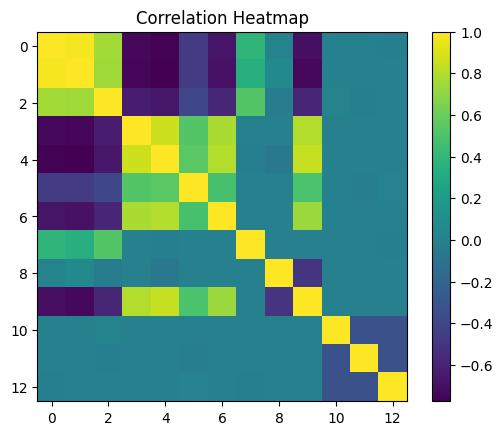

In [4]:
# Correlation heatmap
corr = df.corr()

plt.figure()
plt.imshow(corr)
plt.colorbar()
plt.title('Correlation Heatmap')
plt.show()


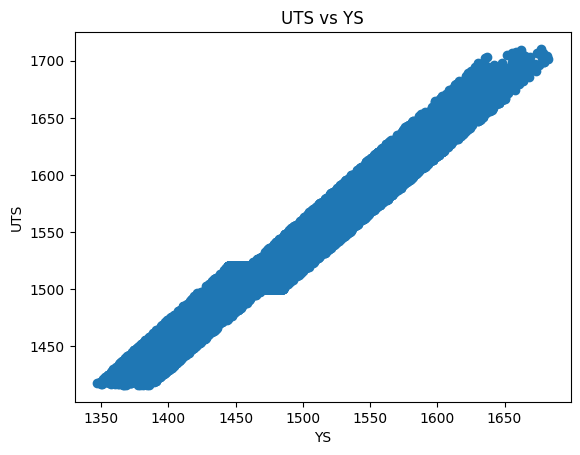

In [5]:
# Scatter plot UTS vs YS
plt.figure()
plt.scatter(df['YS'], df['UTS'])
plt.xlabel('YS')
plt.ylabel('UTS')
plt.title('UTS vs YS')
plt.show()


In [6]:
# Train-test split
X = df.drop('UTS', axis=1)
y = df['UTS']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)


In [7]:
# Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [8]:
# Model training (Random Forest)
model = RandomForestRegressor(n_estimators=100)
model.fit(X_train, y_train)


RandomForestRegressor()

In [9]:
# Evaluation
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)

print('R2 Score:', r2)
print('RMSE:', rmse)


TypeError: got an unexpected keyword argument 'squared'

In [10]:
# ================================
# 1. IMPORT LIBRARIES
# ================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# ================================
# 2. LOAD DATA
# ================================
df = pd.read_csv("M250_S139_S200_separate_dataset_4000_samples.csv")

print(df.head())
print(df.info())

# ================================
# 3. DATA PREPROCESSING
# ================================

# Drop ID column
df = df.drop(columns=['Sample_ID'])

# One-hot encoding
df = pd.get_dummies(df, drop_first=True)

# ================================
# 4. INCONSISTENCY CHECK
# ================================
# UTS should be >= YS
inconsistent = df[df['UTS'] < df['YS']]
print("Inconsistent rows:", len(inconsistent))

# ================================
# 5. OUTLIER DETECTION (IQR)
# ================================
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1

outliers = ((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR)))
print("Outliers per column:\n", outliers.sum())

# ================================
# 6. CORRELATION HEATMAP
# ================================
corr = df.corr()

plt.figure()
plt.imshow(corr)
plt.colorbar()
plt.title("Correlation Heatmap")
plt.show()

# ================================
# 7. EDA VISUALIZATION
# ================================

# Histogram
df['UTS'].hist()
plt.title("UTS Distribution")
plt.show()

# Scatter plot
plt.figure()
plt.scatter(df['YS'], df['UTS'])
plt.xlabel("Yield Strength (YS)")
plt.ylabel("Ultimate Tensile Strength (UTS)")
plt.title("UTS vs YS")
plt.show()

# ================================
# 8. FEATURE & TARGET
# ================================
X = df.drop('UTS', axis=1)
y = df['UTS']

# ================================
# 9. TRAIN-TEST SPLIT
# ================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ================================
# 10. FEATURE SCALING
# ================================
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ================================
# 11. MODEL (RANDOM FOREST)
# ================================
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

# ================================
# 12. PREDICTION
# ================================
y_pred = rf.predict(X_test)

# ================================
# 13. EVALUATION (FIXED RMSE)
# ================================
r2 = r2_score(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("R2 Score:", r2)
print("RMSE:", rmse)

# ================================
# 14. HYPERPARAMETER TUNING
# ================================
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)

# ================================
# 15. FINAL MODEL
# ================================
best_model = grid.best_estimator_

y_pred_best = best_model.predict(X_test)

r2_best = r2_score(y_test, y_pred_best)
rmse_best = np.sqrt(mean_squared_error(y_test, y_pred_best))

print("Final R2:", r2_best)
print("Final RMSE:", rmse_best)

# ================================
# 16. FEATURE IMPORTANCE
# ================================
importances = best_model.feature_importances_

feature_names = X.columns

plt.figure()
plt.barh(feature_names, importances)
plt.title("Feature Importance")
plt.show()

   Sample_ID Specimen_Type Condition          UTS           YS        K1c  \
0          0          S139        R0  1571.246957  1511.419667  72.922086   
1          0          S139        R1  1500.000000  1472.781168  68.614391   
2          0          S139        R2  1455.678161  1392.864565  66.576502   
3          1          S200        R0  1558.694670  1530.178294  77.958042   
4          1          S200        R1  1500.000000  1473.462267  74.350428   

   Elongation  HAZ_Width  Gauge_Depth Repair_Location  Austenite_Content  
0    6.727071   1.455504     4.826599            Root           2.214239  
1    8.433015   1.821937     4.926599            Root           3.932652  
2    9.998795   2.335660     5.026599            Root           5.524272  
3    6.932592   1.105366     4.922047            Root           2.933349  
4    8.829706   1.438231     5.022047            Root           5.245898  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data column

TypeError: numpy boolean subtract, the `-` operator, is not supported, use the bitwise_xor, the `^` operator, or the logical_xor function instead.

   Sample_ID Specimen_Type Condition          UTS           YS        K1c  \
0          0          S139        R0  1571.246957  1511.419667  72.922086   
1          0          S139        R1  1500.000000  1472.781168  68.614391   
2          0          S139        R2  1455.678161  1392.864565  66.576502   
3          1          S200        R0  1558.694670  1530.178294  77.958042   
4          1          S200        R1  1500.000000  1473.462267  74.350428   

   Elongation  HAZ_Width  Gauge_Depth Repair_Location  Austenite_Content  
0    6.727071   1.455504     4.826599            Root           2.214239  
1    8.433015   1.821937     4.926599            Root           3.932652  
2    9.998795   2.335660     5.026599            Root           5.524272  
3    6.932592   1.105366     4.922047            Root           2.933349  
4    8.829706   1.438231     5.022047            Root           5.245898  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data column

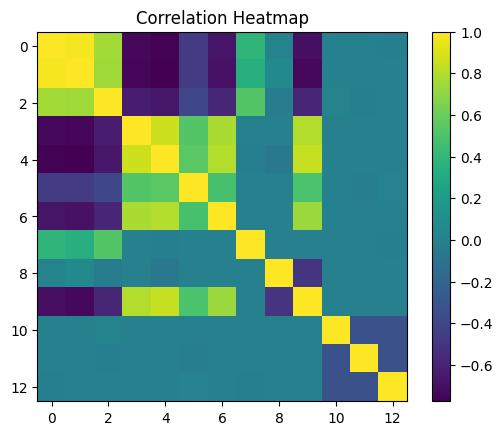

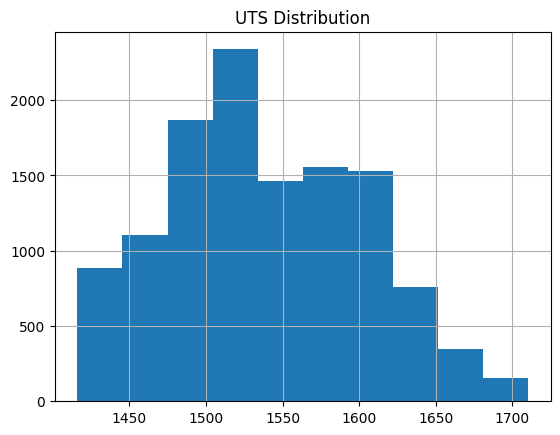

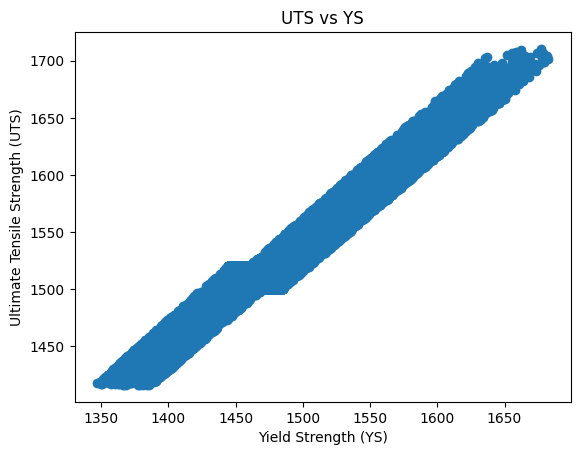

Base Model R2: 0.9627669291795349
Base Model RMSE: 12.378260516595521
Best Parameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
Final R2: 0.964198888454734
Final RMSE: 12.137896946539069


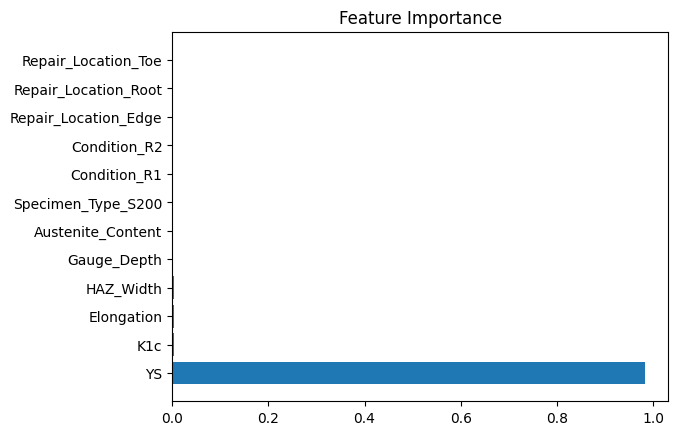

In [11]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# ==========================================
# 2. LOAD DATA
# ==========================================
df = pd.read_csv("M250_S139_S200_separate_dataset_4000_samples.csv")

print(df.head())
print(df.info())

# ==========================================
# 3. DATA CLEANING
# ==========================================
# Drop ID column
df = df.drop(columns=['Sample_ID'])

# ==========================================
# 4. INCONSISTENCY CHECK
# ==========================================
# UTS should always be >= YS
inconsistent = df[df['UTS'] < df['YS']]
print("Inconsistent rows:", len(inconsistent))

# ==========================================
# 5. OUTLIER DETECTION (FIXED)
# ==========================================
# Use only numeric columns
numeric_df = df.select_dtypes(include=[np.number])

Q1 = numeric_df.quantile(0.25)
Q3 = numeric_df.quantile(0.75)
IQR = Q3 - Q1

outliers = ((numeric_df < (Q1 - 1.5 * IQR)) |
            (numeric_df > (Q3 + 1.5 * IQR)))

print("Outliers per column:\n", outliers.sum())

# OPTIONAL: Remove outliers
df_clean = df[~outliers.any(axis=1)]
print("Shape after removing outliers:", df_clean.shape)

# ==========================================
# 6. ENCODING (AFTER OUTLIER HANDLING)
# ==========================================
df_clean = pd.get_dummies(df_clean, drop_first=True)

# ==========================================
# 7. CORRELATION HEATMAP
# ==========================================
corr = df_clean.corr()

plt.figure()
plt.imshow(corr)
plt.colorbar()
plt.title("Correlation Heatmap")
plt.show()

# ==========================================
# 8. EDA VISUALIZATION
# ==========================================

# Histogram
plt.figure()
df_clean['UTS'].hist()
plt.title("UTS Distribution")
plt.show()

# Scatter plot
plt.figure()
plt.scatter(df_clean['YS'], df_clean['UTS'])
plt.xlabel("Yield Strength (YS)")
plt.ylabel("Ultimate Tensile Strength (UTS)")
plt.title("UTS vs YS")
plt.show()

# ==========================================
# 9. FEATURE & TARGET
# ==========================================
X = df_clean.drop('UTS', axis=1)
y = df_clean['UTS']

# ==========================================
# 10. TRAIN-TEST SPLIT
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ==========================================
# 11. FEATURE SCALING
# ==========================================
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ==========================================
# 12. BASE MODEL (RANDOM FOREST)
# ==========================================
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

# ==========================================
# 13. EVALUATION (FIXED RMSE)
# ==========================================
r2 = r2_score(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("Base Model R2:", r2)
print("Base Model RMSE:", rmse)

# ==========================================
# 14. HYPERPARAMETER TUNING
# ==========================================
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)

# ==========================================
# 15. FINAL MODEL
# ==========================================
best_model = grid.best_estimator_

y_pred_best = best_model.predict(X_test)

r2_best = r2_score(y_test, y_pred_best)
rmse_best = np.sqrt(mean_squared_error(y_test, y_pred_best))

print("Final R2:", r2_best)
print("Final RMSE:", rmse_best)

# ==========================================
# 16. FEATURE IMPORTANCE
# ==========================================
importances = best_model.feature_importances_
feature_names = X.columns

plt.figure()
plt.barh(feature_names, importances)
plt.title("Feature Importance")
plt.show()